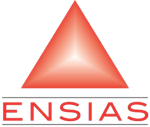

# TP 4 — K plus proches voisins (KNN)

**Module :** Introduction au Machine Learning
**Enseignant :** Prof. Aissam BERRAHOU — ENSIAS, Université Mohammed V de Rabat
**Niveau :** 2e année cycle ingénieur
**Durée estimée :** 2 heures
**Support associé :** Lecture 4 — KNN

## 1. Objectifs pédagogiques

*Ce TP prolonge le cours : vous allez refaire sur machine les calculs vus en séance, puis passer à un vrai jeu de données.*

1. Implémenter KNN **« from scratch »** avec NumPy (distances euclidienne et Manhattan, vote).
2. Retrouver l'exemple des slides : classer la fleur $I(20, 24)$.
3. Utiliser `KNeighborsClassifier` sur la base Iris et l'évaluer.
4. Choisir $k$ par **validation croisée** et visualiser les **frontières de décision**.
5. Mesurer l'effet de la **normalisation**.

## 2. Rappel théorique

*Avant de coder, un rapide rappel des formules dont nous aurons besoin.*

Pour classer un point $x$ :
1. calculer la distance entre $x$ et chaque exemple d'apprentissage ;
2. garder les $k$ exemples les plus proches ;
3. **classification** : étiquette majoritaire ; **régression** : moyenne des étiquettes.

$$d_{\text{euclidienne}}(x, y) = \sqrt{\sum_j (x_j - y_j)^2} \qquad d_{\text{Manhattan}}(x, y) = \sum_j |x_j - y_j|$$

## 3. Import des bibliothèques

*On charge d'abord les outils. Tout le TP n'utilise que NumPy, pandas, Matplotlib et scikit-learn.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

## 4. Exemple jouet : la fleur $I(20, 24)$

*Une nouvelle fleur arrive. Ses voisines vont-elles nous dire à quelle catégorie elle appartient ?*

Les 6 fleurs étiquetées des slides :

In [2]:
X_fleurs = np.array([[22, 17], [27, 25], [25, 24], [15, 35], [13, 25], [12, 30]], dtype=float)
y_fleurs = np.array([1, 1, 1, 2, 2, 2])          # catégorie de chaque fleur
noms = ["O1", "O2", "O3", "O4", "O5", "O6"]
inconnu = np.array([20, 24])                      # la fleur à classer
pd.DataFrame(X_fleurs, index=noms, columns=["T. pétales", "T. tige"]).assign(catégorie=y_fleurs)

,T. pétales,T. tige,catégorie
O1,22.0,17.0,1
O2,27.0,25.0,1
O3,25.0,24.0,1
O4,15.0,35.0,2
O5,13.0,25.0,2
O6,12.0,30.0,2


### 4.1 Étape 1 : distances

*Première question : à quelle distance se trouve chaque fleur ?*

In [3]:
d_euclid = np.sqrt(((X_fleurs - inconnu) ** 2).sum(axis=1))   # √(Σ (x_j - y_j)²)
d_manhattan = np.abs(X_fleurs - inconnu).sum(axis=1)           # Σ |x_j - y_j|

tableau = pd.DataFrame({"catégorie": y_fleurs, "d euclidienne": d_euclid.round(2),
                        "d Manhattan": d_manhattan}, index=noms)
tableau

,catégorie,d euclidienne,d Manhattan
O1,1,7.28,9.0
O2,1,7.07,8.0
O3,1,5.00,5.0
O4,2,12.08,16.0
O5,2,7.07,8.0
O6,2,10.00,14.0


### 4.2 Étape 2 : tri et vote

*Ensuite, on donne la parole aux k plus proches voisines.*

On écrit une fonction qui fait les deux étapes :

In [4]:
def knn_predire(X, y, x_nouveau, k, distance="euclidienne"):
    """Renvoie la catégorie majoritaire parmi les k plus proches voisins."""
    if distance == "euclidienne":
        d = np.sqrt(((X - x_nouveau) ** 2).sum(axis=1))
    else:
        d = np.abs(X - x_nouveau).sum(axis=1)
    voisins = np.argsort(d, kind="stable")[:k]        # indices des k plus proches
    etiquettes, votes = np.unique(y[voisins], return_counts=True)
    return etiquettes[np.argmax(votes)]               # étiquette la plus fréquente

In [5]:
for k in [1, 3, 5]:
    for dist in ["euclidienne", "manhattan"]:
        print(f"k = {k}, distance {dist:12s} -> catégorie {knn_predire(X_fleurs, y_fleurs, inconnu, k, dist)}")

k = 1, distance euclidienne  -> catégorie 1
k = 1, distance manhattan    -> catégorie 1
k = 3, distance euclidienne  -> catégorie 1
k = 3, distance manhattan    -> catégorie 1
k = 5, distance euclidienne  -> catégorie 1
k = 5, distance manhattan    -> catégorie 1


✅ Comme dans les slides : la fleur $I$ est classée dans la **catégorie 1** pour $k = 1, 3, 5$.

### 4.3 Vérification avec scikit-learn

*scikit-learn prend-il la même décision ?*

In [6]:
for k in [1, 3, 5]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_fleurs, y_fleurs)
    print(f"k = {k} -> {knn.predict([inconnu])}")

k = 1 -> [1]
k = 3 -> [1]
k = 5 -> [1]


### 4.4 Visualisation

*Voyons sur un graphique qui sont les trois voisines retenues.*

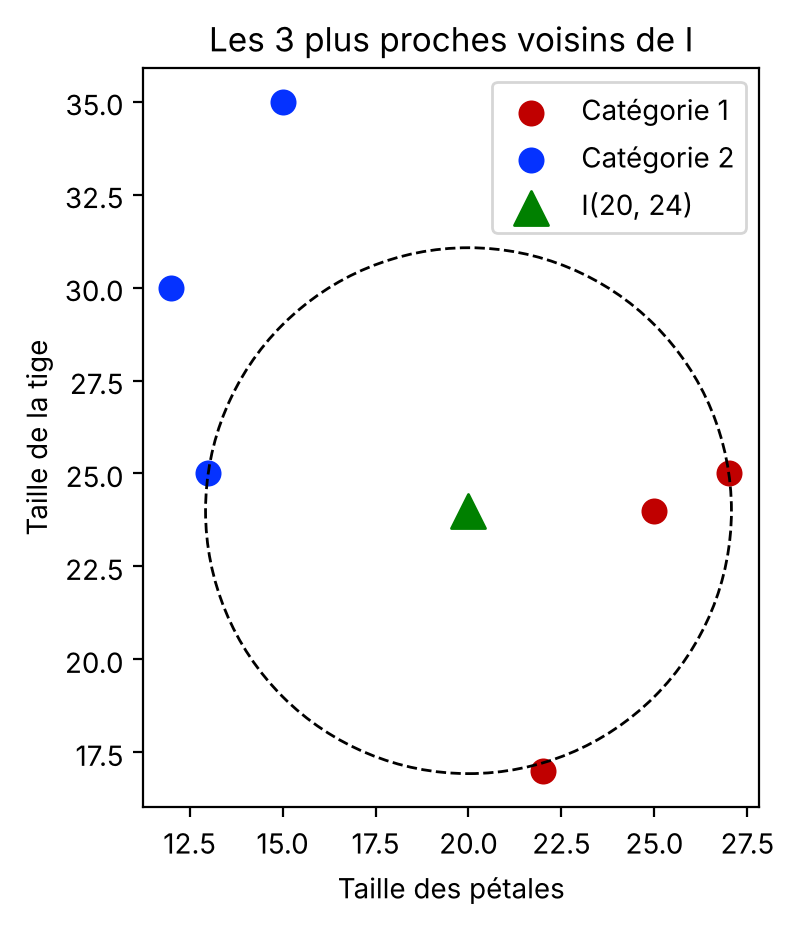

In [7]:
plt.scatter(*X_fleurs[y_fleurs == 1].T, c="#C00000", s=70, label="Catégorie 1")
plt.scatter(*X_fleurs[y_fleurs == 2].T, c="#0532FF", s=70, label="Catégorie 2")
plt.scatter(*inconnu, c="green", marker="^", s=150, label="I(20, 24)")
cercle = plt.Circle(inconnu, np.sort(d_euclid)[2], fill=False, ls="--")   # rayon du 3e voisin
plt.gca().add_patch(cercle); plt.gca().set_aspect("equal")
plt.xlabel("Taille des pétales"); plt.ylabel("Taille de la tige")
plt.title("Les 3 plus proches voisins de I"); plt.legend(); plt.show()

## 5. Cas pratique : la base Iris

*Passons à 150 fleurs et trois espèces : KNN tient-il la route ?*

150 fleurs, 4 mesures, 3 espèces. On garde 30 % des données pour le test.

In [8]:
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=42, stratify=iris.target)
print(X_train.shape, X_test.shape)

(105, 4) (45, 4)


In [9]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)                       # « apprentissage » = mémorisation
y_pred = knn.predict(X_test)
print("Exactitude sur le test :", round(accuracy_score(y_test, y_pred), 3))

Exactitude sur le test : 0.978


### 5.1 Évaluation : matrice de confusion

*Quelles espèces le modèle confond-il ?*

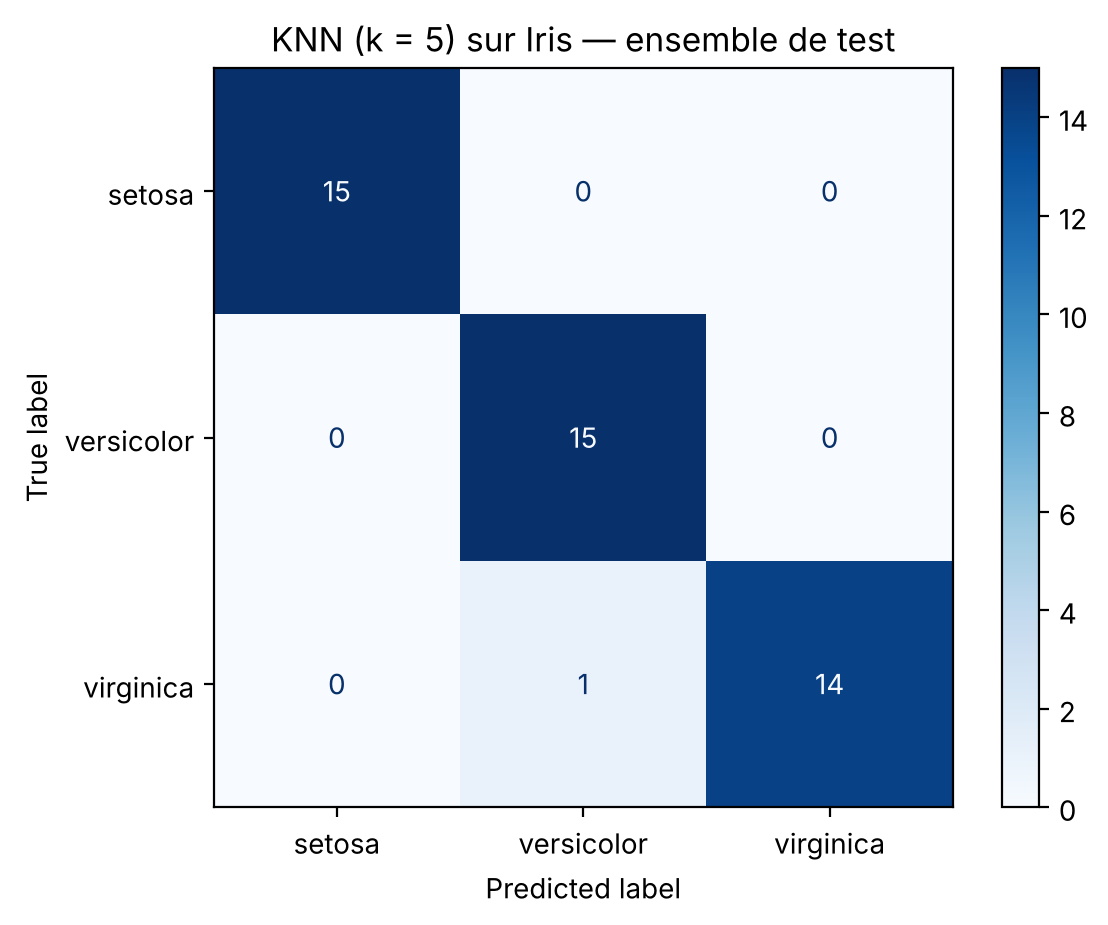

In [10]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=iris.target_names).plot(cmap="Blues")
plt.title("KNN (k = 5) sur Iris — ensemble de test"); plt.show()

## 6. Influence de $k$

*Combien de voisins faut-il écouter ?*

### 6.1 Choisir $k$ par validation croisée (sur l'apprentissage uniquement)

*On choisit k sans jamais regarder l'ensemble de test.*

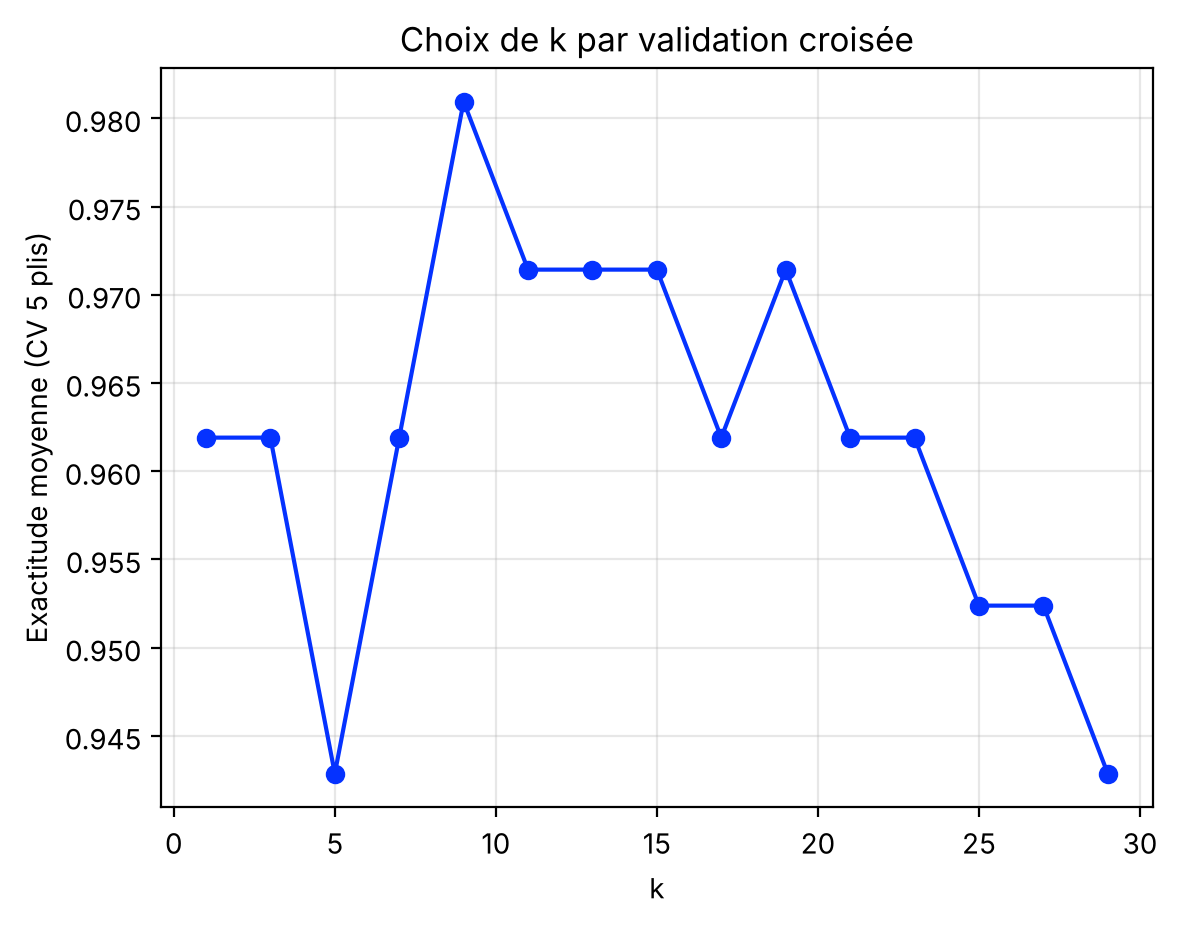

Meilleur k : 9


In [11]:
valeurs_k = range(1, 31, 2)
scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in valeurs_k]
plt.plot(valeurs_k, scores, "o-", color="#0532FF")
plt.xlabel("k"); plt.ylabel("Exactitude moyenne (CV 5 plis)")
plt.title("Choix de k par validation croisée"); plt.grid(alpha=0.3); plt.show()
meilleur_k = list(valeurs_k)[int(np.argmax(scores))]
print("Meilleur k :", meilleur_k)

### 6.2 Frontières de décision (2 variables : longueur et largeur des pétales)

*À quoi ressemble la frontière quand k change ?*

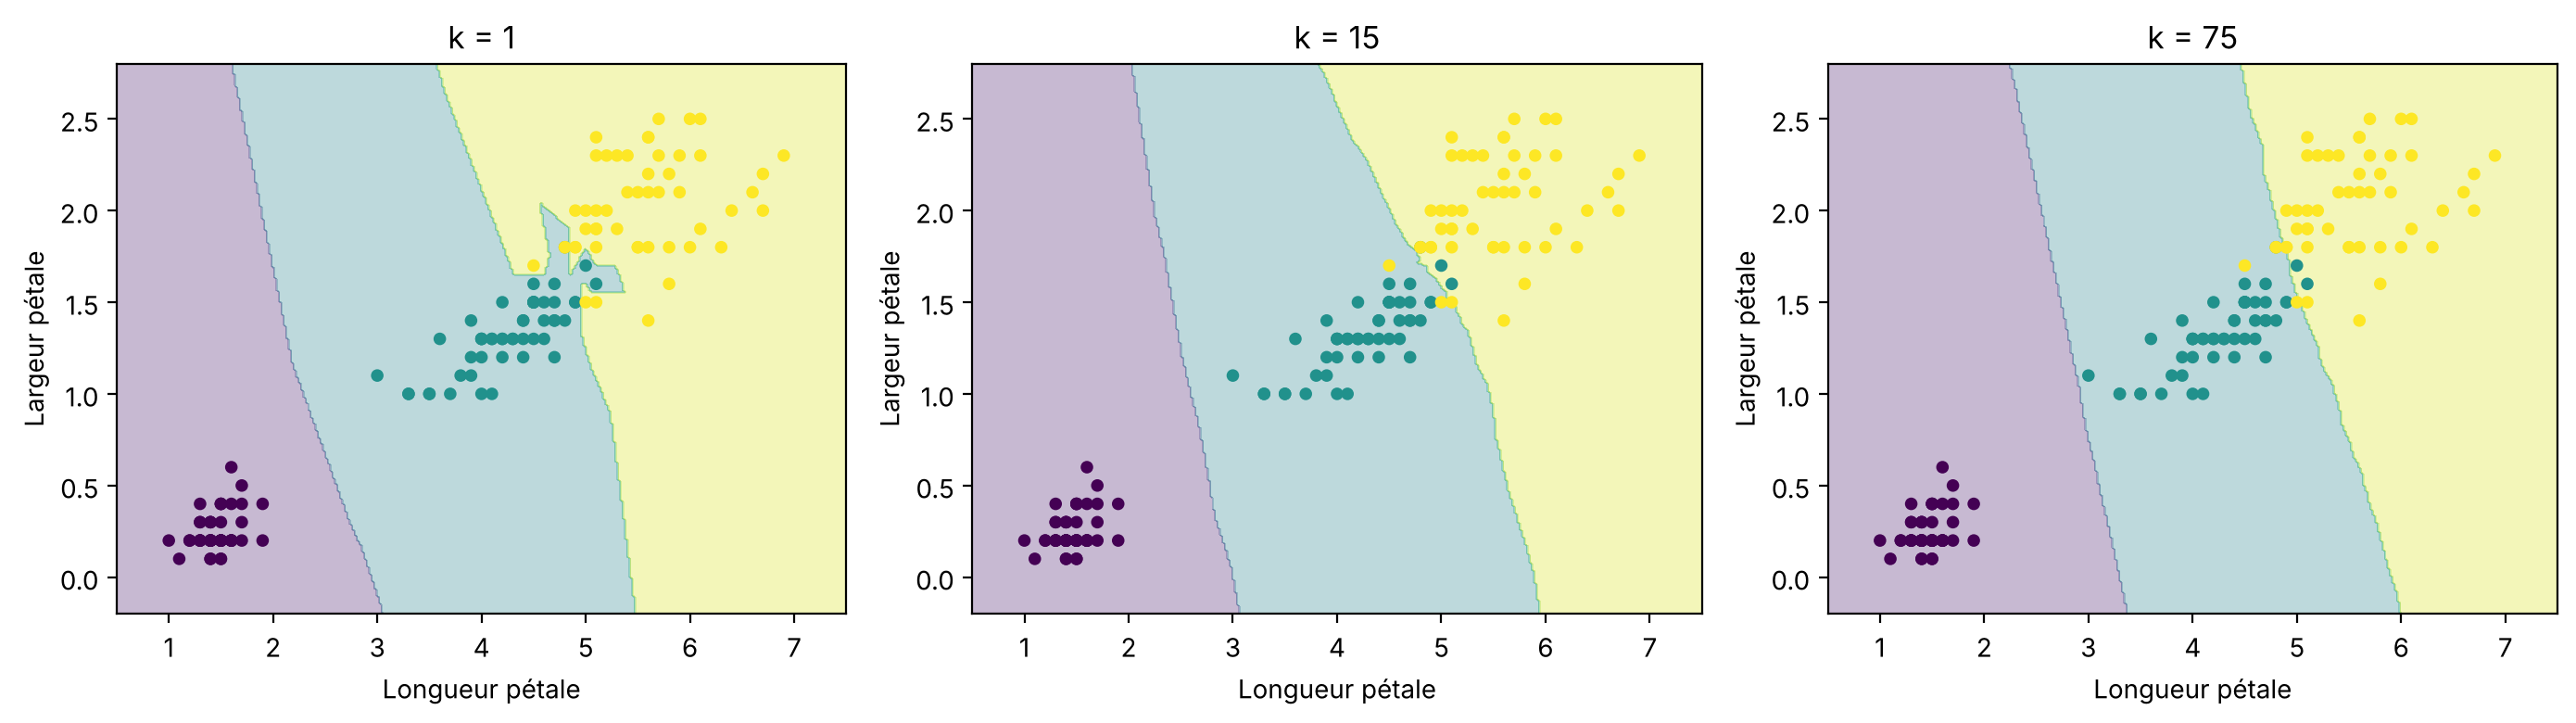

In [12]:
def tracer_frontiere(k, ax):
    X2 = iris.data[:, 2:4]                                        # pétales seulement
    modele = KNeighborsClassifier(n_neighbors=k).fit(X2, iris.target)
    xx, yy = np.meshgrid(np.linspace(0.5, 7.5, 300), np.linspace(-0.2, 2.8, 300))
    Z = modele.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    ax.scatter(X2[:, 0], X2[:, 1], c=iris.target, s=15, cmap="viridis")
    ax.set_title(f"k = {k}"); ax.set_xlabel("Longueur pétale"); ax.set_ylabel("Largeur pétale")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for k, ax in zip([1, 15, 75], axes):
    tracer_frontiere(k, ax)
plt.tight_layout(); plt.show()

- $k = 1$ : frontière très irrégulière (surapprentissage) ;
- $k = 15$ : frontière lisse et raisonnable ;
- $k = 75$ : le vote est dominé par les grandes classes (sous-apprentissage).

### 6.3 Normalisation : la base Wine

*Que se passe-t-il quand une variable est mille fois plus grande que les autres ?*

Les variables de Wine ont des échelles très différentes (ex. *proline* ≈ 1000, *hue* ≈ 1).

In [13]:
wine = load_wine()
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    wine.data, wine.target, test_size=0.3, random_state=42, stratify=wine.target)

sans = KNeighborsClassifier(5).fit(Xw_train, yw_train)
avec = make_pipeline(StandardScaler(), KNeighborsClassifier(5)).fit(Xw_train, yw_train)
print("Sans normalisation :", round(sans.score(Xw_test, yw_test), 3))
print("Avec normalisation :", round(avec.score(Xw_test, yw_test), 3))

Sans normalisation : 0.722
Avec normalisation : 0.944


La normalisation améliore fortement le résultat : sans elle, *proline* domine toutes les distances.

## 7. Exercices

*À vous de jouer ! Les exercices sont classés du plus simple au plus exigeant. Essayez de les faire sans regarder les solutions.*

### Exercice 1 (facile) — Un autre point
Classez la fleur $J(18, 28)$ avec $k = 1, 3, 5$ et les deux distances, d'abord à la main (avec `knn_predire`), puis avec scikit-learn.

In [14]:
# À compléter

### Exercice 2 (moyen) — KNN en régression
On donne à chaque fleur une « valeur » $v = (4.5, 5.0, 4.8, 2.0, 2.4, 2.1)$. Prédisez $v$ pour $I(20, 24)$ avec $k = 3$ (moyenne des voisins), à la main puis avec `KNeighborsRegressor`.

In [15]:
# À compléter
valeurs = np.array([4.5, 5.0, 4.8, 2.0, 2.4, 2.1])

### Exercice 3 (défi) — Vote pondéré par la distance
Modifiez `knn_predire` pour que chaque voisin vote avec un poids $1/d$. Comparez avec `KNeighborsClassifier(weights="distance")` sur Iris (validation croisée, $k = 15$).

In [16]:
# À compléter

## 8. Solutions

*Comparez vos réponses avec les propositions ci-dessous ; il existe souvent plusieurs façons correctes de faire.*

<details>
<summary><b>Solution de l'exercice 1</b> (cliquer pour afficher)</summary>

```python
J = np.array([18, 28])
for k in [1, 3, 5]:
    print(k, knn_predire(X_fleurs, y_fleurs, J, k), knn_predire(X_fleurs, y_fleurs, J, k, "manhattan"),
          KNeighborsClassifier(k).fit(X_fleurs, y_fleurs).predict([J]))
```
</details>

<details>
<summary><b>Solution de l'exercice 2</b> (cliquer pour afficher)</summary>

```python
voisins = np.argsort(d_euclid, kind="stable")[:3]      # O3, O2, O5
print(valeurs[voisins].mean())                          # (4.8 + 5.0 + 2.4) / 3 = 4.07
print(KNeighborsRegressor(3).fit(X_fleurs, valeurs).predict([inconnu]))
```
</details>

<details>
<summary><b>Solution de l'exercice 3</b> (cliquer pour afficher)</summary>

```python
def knn_pondere(X, y, x_nouveau, k):
    d = np.sqrt(((X - x_nouveau) ** 2).sum(axis=1))
    voisins = np.argsort(d)[:k]
    poids = {}
    for i in voisins:
        poids[y[i]] = poids.get(y[i], 0) + 1 / (d[i] + 1e-9)   # vote 1/d
    return max(poids, key=poids.get)

for w in ["uniform", "distance"]:
    print(w, cross_val_score(KNeighborsClassifier(15, weights=w), X_train, y_train, cv=5).mean().round(3))
```
</details>

## 9. Conclusion — ce qu'il faut retenir

*Avant de passer à la suite, prenons une minute pour résumer l'essentiel.*

- KNN prédit à partir des **k plus proches voisins** : il n'y a pas de vrai apprentissage, tout se passe à la prédiction.
- Le choix de **k** règle le compromis surapprentissage / sous-apprentissage : on le choisit par **validation croisée**.
- Il faut **normaliser** les variables avant de calculer des distances.
- KNN est simple, mais lent sur de grands jeux de données et mauvais en grande dimension.

➡️ Prochain cours : les SVM.